**BAGIAN 1**

In [11]:
!git clone https://github.com/SuciOktavia02/simuteh-2330511010.git /content/simuteh
%cd /content/simuteh/notebook
import os
print(os.getcwd())
print("src   :", os.listdir("../src") if os.path.exists("../src") else "TIDAK ADA")
print("hasil :", os.listdir("../hasil") if os.path.exists("../hasil") else "TIDAK ADA")
print("data  :", os.path.exists("../data/sintetis/label.csv"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 338, done.
remote: Counting objects: 100% (101/101), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 338 (delta 21), reused 80 (delta 9), pack-reused 237 (from 2)
Receiving objects: 100% (338/338), 88.16 MiB | 20.25 MiB/s, done.
Resolving deltas: 100% (35/35), done.
/content/simuteh/notebook
/content/simuteh/notebook
src   : ['utils_tepi.py', 'praproses_acuan.py', 'praproses.py', 'buat_dataset_sintetis.py', 'utils_cv.py']
hasil : ['b3_perbaikan_gelap.png', 'b3_gambar4_perbandingan.png', 'b5_pipeline_final.png', 'b3_perbaikan_bayangan.png', 'b5_tabel12.csv', 'b2_kb_kanal_ringan.csv', 'b4_median_kernel.csv', 'b3_perbaikan_terang.png', 'b3_kb_kandidat_per_kondisi.csv', 'b3_gambar4_bagian1.png', 'b2_panel_kanal.png', 'b3_histogram_5kondisi.png', 'b4_crop_bercak.png', 'b1_pipeline.png', 'b4_di_kb_kernel.png', 'b3_histogram_ringan.png', 'b2_kb_kanal.csv', 'b4_psnr_12_normal.csv', 'b3_gambar4_bagian3.png', 'b

In [16]:
%cd /content/simuteh/notebook

/content/simuteh/notebook


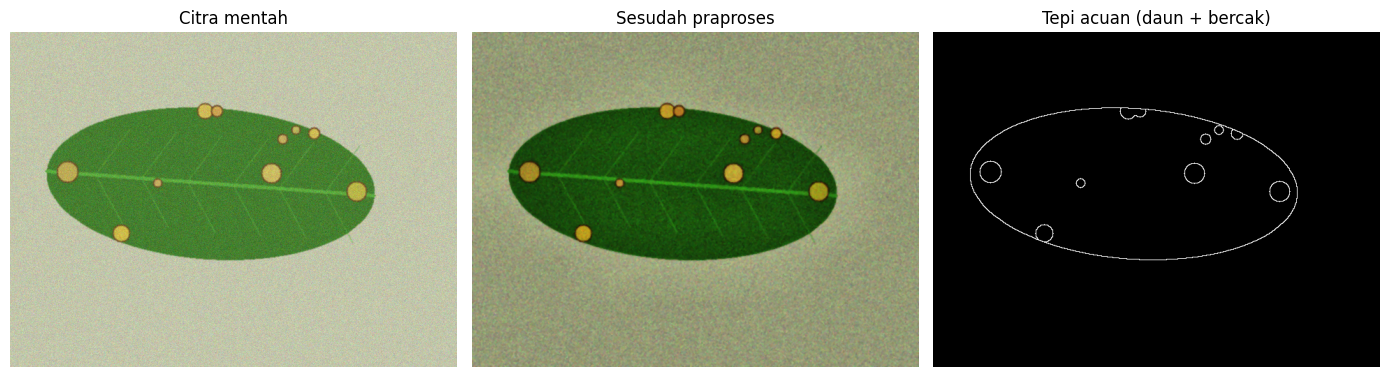

In [19]:
# ===== Kode 1.1 | Persiapan: modul, data, praproses, dan tepi acuan =====
import sys, json, os
# Memastikan path mengarah ke folder src yang tepat
sys.path.append(os.path.abspath("../src"))

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 592.8


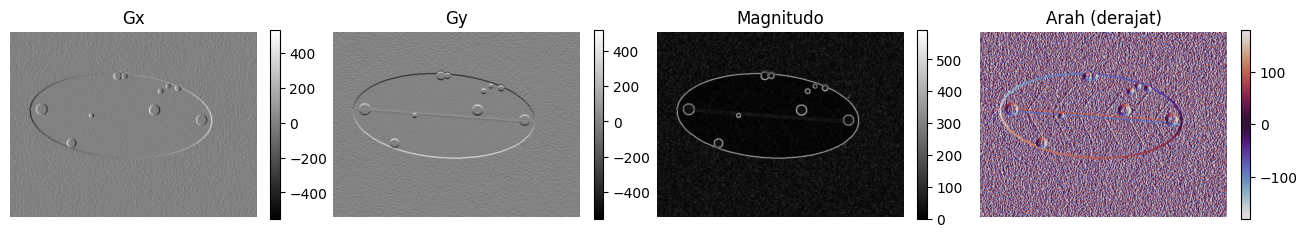

In [20]:
# ===== Kode 1.2 | Gradien Sobel manual: Gx, Gy, magnitudo, dan arah =====
g = pra[:, :, 2].astype(np.float32)   # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)
gy = cv2.filter2D(g, cv2.CV_32F, ky)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.savefig("../hasil/p5_gradien_sobel.png", dpi=110, bbox_inches="tight")

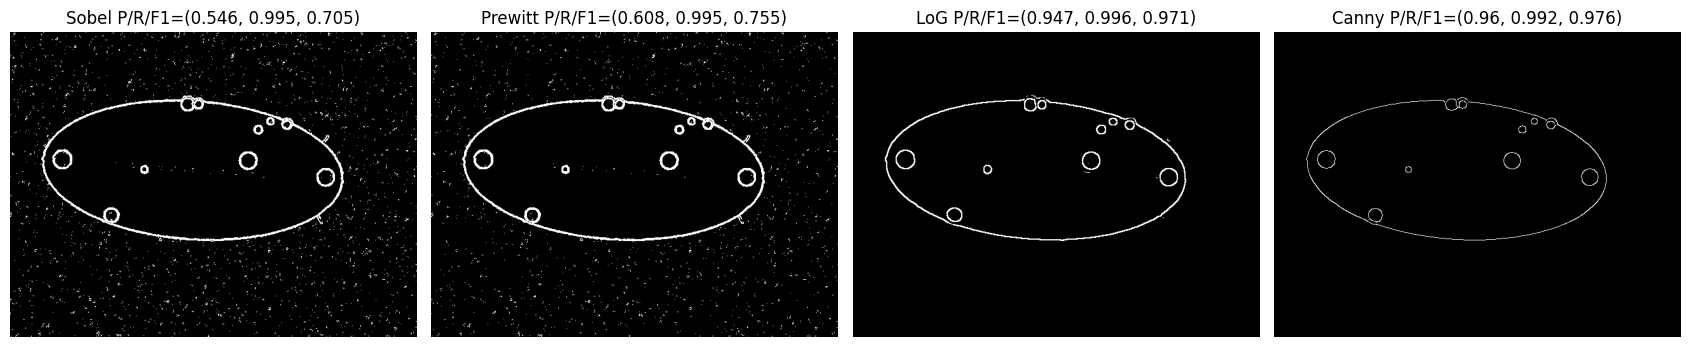

In [21]:
# ===== Kode 1.3 | Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya =====
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_panel_operator.png", dpi=110, bbox_inches="tight")

In [22]:
# ===== Kode 1.4 | Tabel presisi, recall, dan F1 tepi (40 citra berbercak) =====
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.742  0.752  0.744
                LoG      0.628  0.998  0.763
                Prewitt  0.783  0.965  0.854
                Sobel    0.746  0.972  0.831
          R     Canny    0.988  0.981  0.984
                LoG      0.894  0.997  0.937
                Prewitt  0.520  0.997  0.631
                Sobel    0.457  0.997  0.569
praproses Gray  Canny    0.850  0.923  0.877
                LoG      0.588  0.996  0.728
                Prewitt  0.759  0.990  0.854
                Sobel    0.747  0.990  0.846
          R     Canny    0.978  0.991  0.984
                LoG      0.868  0.992  0.918
                Prewitt  0.574  0.997  0.695
                Sobel    0.524  0.997  0.650


metode          Canny    LoG  Prewitt  Sobel
kondisi                                     
bayangan        0.986  0.923    0.691  0.650
gelap           0.976  0.944    0.630  0.580
kontras_rendah  0.990  0.833    0.863  0.824
normal          0.982  0.957    0.586  0.542
terang          0.987  0.932    0.704  0.653


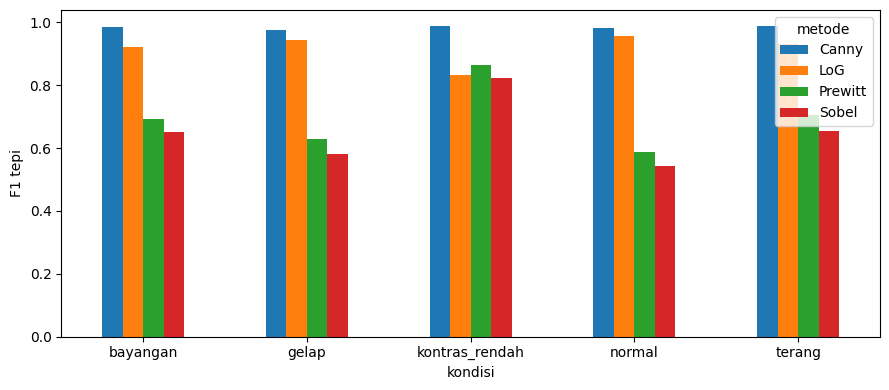

In [23]:
# ===== Langkah 1.5 | Grafik F1 tepi per kondisi cahaya (kanal R, sesudah praproses) =====
sub = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
pv = sub.pivot_table(index="kondisi", columns="metode", values="F1").round(3)
print(pv)
pv.plot(kind="bar", figsize=(9, 4)); plt.ylabel("F1 tepi"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("../hasil/p5_f1_kondisi.png", dpi=110)

**BAGIAN 2**

In [24]:
# ===== Kode 2.1 | Eksperimen sigma dan ambang Canny =====
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))
canny.to_csv("../hasil/p5_canny_eksperimen.csv", index=False)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.660  0.992  0.746     0.969
      30/90    0.025  0.997  0.049     0.981
      50/150   0.210  0.995  0.281     0.975
1.0   100/200  0.977  0.975  0.975     0.886
      30/90    0.414  0.994  0.499     0.972
      50/150   0.962  0.993  0.977     0.962
2.0   100/200  0.792  0.756  0.772     0.632
      30/90    0.978  0.991  0.984     0.953
      50/150   0.937  0.907  0.920     0.733
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.967   0.970
      30/90    0.986   0.976
      50/150   0.977   0.973
1.0   100/200  0.910   0.862
      30/90    0.976   0.968
      50/150   0.968   0.957
2.0   100/200  0.683   0.582
      30/90    0.957   0.950
      50/150   0.752   0.713


In [25]:
# ===== Kode 2.2 | Ambang Canny otomatis berbasis median =====
def canny_otomatis(g, s=0.33):
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.243  0.644           0.897   0.780   0.976
      tetap 30/90     0.830  0.853           0.920   0.850   0.929
R     otomatis        0.098  0.293           0.666   0.725   0.959
      tetap 30/90     0.986  0.976           0.990   0.982   0.987
kanal  kondisi       
Gray   bayangan           63.9
       gelap              95.2
       kontras_rendah    113.6
       normal            149.1
       terang            189.0
R      bayangan           71.2
       gelap             113.1
       kontras_rendah    116.8
       normal            164.9
       terang            198.5
Name: median, dtype: float64


In [26]:
# ===== Bahan P2.3 | Ambang otomatis vs besar gradien di tepi daun (kontras_rendah) =====
def mag_l1(g):
    g = g.astype(np.float32)
    return np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(g, cv2.CV_32F, 0, 1))

baris = []
sub = label[(label.kelas != "sehat") & (label.kondisi_cahaya == "kontras_rendah")]
for _, d in sub.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    tepi = tepi_acuan(md) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        v = np.median(g)
        m0 = mag_l1(g)                                   # tanpa penghalusan
        m2 = mag_l1(cv2.GaussianBlur(g, (0, 0), 2.0))    # sesudah Gaussian sigma 2
        baris.append([kanal, v, 0.67 * v, 1.33 * v,
                      np.median(m0[tepi]), np.median(m2[tepi])])
gr = pd.DataFrame(baris, columns=["kanal", "median", "auto_bawah", "auto_atas",
                                  "grad_tepi_tanpa_halus", "grad_tepi_sigma2"])
print(gr.groupby("kanal").mean().round(1))

       median  auto_bawah  auto_atas  grad_tepi_tanpa_halus  grad_tepi_sigma2
kanal                                                                        
Gray    113.6        76.1      151.1             149.399994              87.0
R       116.8        78.2      155.3             201.500000             120.0


In [27]:
# ===== Uji tambahan | Ambang otomatis dengan penghalusan sigma 2 =====
def canny_otomatis_halus(g, s=0.33, sigma=2.0):
    return canny_otomatis(cv2.GaussianBlur(g, (0, 0), sigma), s)

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, skor_tepi(canny_otomatis_halus(g), ac)[2]])
adil = pd.DataFrame(baris, columns=["kondisi", "kanal", "F1"])
print(adil.pivot_table(index="kanal", columns="kondisi", values="F1").round(3))

kondisi  bayangan  gelap  kontras_rendah  normal  terang
kanal                                                   
Gray        0.815  0.892           0.000   0.920   0.000
R           0.986  0.985           0.439   0.984   0.946


In [28]:
# ===== Langkah 2.4 | Canny dengan ambang dari persentil magnitudo =====
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    gh = cv2.GaussianBlur(g, (0, 0), sigma)                         # (1) haluskan
    gx = cv2.Sobel(gh, cv2.CV_32F, 1, 0); gy = cv2.Sobel(gh, cv2.CV_32F, 0, 1)
    mag = np.hypot(gx, gy)                                           # (2) magnitudo Sobel
    hi = np.percentile(mag, q); lo = rasio * hi                      # (3) ambang dari persentil
    return cv2.Canny(gh, lo, hi, L2gradient=True)                    # (4) Canny (magnitudo L2, sama dengan hypot)

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, q, skor_tepi(canny_persentil(g, q), ac)[2]])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "q", "F1"])
print(pers.pivot_table(index=["kanal", "q"], columns="kondisi", values="F1").round(3))
pers.to_csv("../hasil/p5_canny_persentil.csv", index=False)

kondisi   bayangan  gelap  kontras_rendah  normal  terang
kanal q                                                  
Gray  90     0.097  0.077           0.064   0.080   0.083
      95     0.388  0.518           0.291   0.550   0.533
      98     0.788  0.775           0.855   0.884   0.840
R     90     0.099  0.074           0.072   0.078   0.081
      95     0.243  0.183           0.177   0.348   0.456
      98     0.984  0.981           0.991   0.987   0.993


kanal            Gray    R
kondisi                   
bayangan        152.2  0.0
gelap           428.2  0.0
kontras_rendah    0.0  0.0
normal          488.0  0.0
terang          436.8  0.0


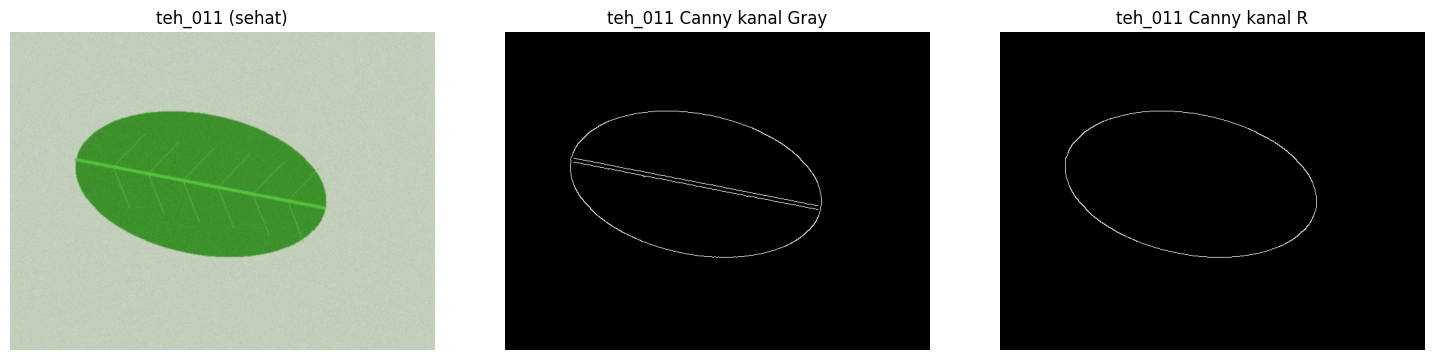

In [29]:
# ===== Kode 2.3 | Tepi palsu di bagian dalam daun sehat =====
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_tepi_sehat.png", dpi=110, bbox_inches="tight")

In [31]:
!git add .
!git commit -m "P5: deteksi tepi (Bagian 1 dan 2)"
!git tag v0.2-tepi
!git push && git push --tags

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@7e01764c1710.(none)')
fatal: could not read Username for 'https://github.com': No such device or address
